# 언어모델&생성모델 과제

# 1. 언어모델

## BERT — Masked Language Modeling

BERT는 Transformer **인코더** 기반의 언어모델로, `[MASK]` 앞뒤 문맥을 활용해 가려진 토큰을 예측합니다.

### 1-1. BERT 모델과 tokenizer 불러오기

In [33]:
from transformers import BertTokenizer, BertForMaskedLM
import torch

# BERT 모델과 tokenizer 초기화
tokenizer = BertTokenizer.from_pretrained('klue/bert-base') # base : 모델크기, (uncased : 소문자 학습)
model = BertForMaskedLM.from_pretrained('klue/bert-base') # base : 모델크기, (uncased : 소문자 학습)
# tokenizer : raw text를 개별 토큰으로 분리(Wordpiece). 토크나이저 사전에 따라 고유한 정수 인덱스(고정값)를 매핑함.

# tokenizer를 통해 생성된 정수 인덱스 : 텍스트를 모델이 읽을 수 있도록 숫자화
# Embedding vector : 단어의 의미적, 문맥적 특성을 모델링
model.eval()  # 사전학습된 가중치로 추론할 때 평가 모드 사용


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: klue/bert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertForMaskedLM(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, el

### 1-2. 문장을 토큰화하고 `[MASK]` 위치 확인하기

In [34]:
# 테스트할 문장
text = "[CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]"

# 문장을 토큰으로 변환
tokenized_text = tokenizer.********(text) # text(문장)을 토큰으로 변환해 tokenized_text에 저장합시다!
indexed_tokens = tokenizer.convert_tokens_to_ids(**************) # 토큰을 index로 변환하는 코드!

print(tokenized_text) # 토큰이 출력됩니다.
print(indexed_tokens) # 인덱스가 출력됩니다.

# 마스킹된 위치 찾기
masked_index = **************.index("[MASK]") # 토큰화된 결과물에서 index 메서드를 통해 [MASK]의 위치를 확인해봅시다!
print(masked_index)

['[CLS]', '열', '##여', '##덟', ',', '우리', '##는', '서로', '##의', '이름', '##을', '처음', '불렀', '##다', '.', '그리고', '스물', '하나', ',', '우린', '[MASK]', '을', '했', '##다', '.', '[SEP]']
[2, 1432, 2173, 3542, 16, 3616, 2259, 4084, 2079, 3934, 2069, 3790, 6895, 2062, 18, 3673, 10514, 3657, 16, 8983, 4, 1498, 1902, 2062, 18, 3]
20


### 1-3. 텐서로 변환하고 `[MASK]` 토큰 예측하기

In [35]:
# 앞에서 만든 정수 ID 목록을 PyTorch 텐서로 변환합니다.
tokens_tensor = *****.******([indexed_tokens])

with torch.no_grad():
    outputs = model(tokens_tensor)
    predictions = outputs.logits

# 전체 logits를 출력하면 매우 길어지므로 차원만 출력합니다.
print("Logits shape:", tuple(predictions.shape))

Logits shape: (1, 26, 32000)


In [36]:
# 예측된 토큰 확인
masked_tokens_before = tokenized_text.copy()
predicted_index = torch.argmax(predictions[0, masked_index]).item() # masked_index에 들어갈 것으로 가장 확률이 높은 인덱스
predicted_token = tokenizer.convert_ids_to_tokens([predicted_index])[0]

# 예측된 토큰으로 마스크 채우기
tokenized_text[masked_index] = predicted_token
# 토큰화된 텍스트를 다시 문자열로 변환
filled_text = tokenizer.convert_tokens_to_string(tokenized_text[1:-1])

print("Original:", text)
print("Masked:", masked_tokens_before)
print("Predicted token:", predicted_token) ; print()

print("Filled sentence:", filled_text)

Original: [CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]
Masked: ['[CLS]', '열', '##여', '##덟', ',', '우리', '##는', '서로', '##의', '이름', '##을', '처음', '불렀', '##다', '.', '그리고', '스물', '하나', ',', '우린', '[MASK]', '을', '했', '##다', '.', '[SEP]']
Predicted token: 사랑

Filled sentence: 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 사랑 을 했다.


### 1-4. 직접 만든 문장에서도 `[MASK]` 예측하기

`fill_mask()` 함수로 두 문장의 예측 결과를 비교해 봅시다. 문장 하나는 직접 바꾸어도 좋습니다.

In [37]:
def fill_mask(input_text):
    # 텍스트를 토큰으로 변환
    tokenized_text = tokenizer.tokenize(input_text)
    indexed_tokens = tokenizer.convert_tokens_to_ids(tokenized_text)

    # 마스킹된 위치 찾기
    masked_index = **************.index("[MASK]") # 토큰화된 텍스트에서 마스킹된 위치를 찾아봅시다!

    # 토큰화된 텍스트 -> 정수인덱스(ID) -> Pytorch 텐서
    tokens_tensor = torch.tensor([indexed_tokens])

    # 모델에 토큰 텐서를 전달하고 예측 수행
    with torch.no_grad():
        outputs = model(tokens_tensor)
        predictions = outputs[0]

    # 예측된 토큰 확인
    predicted_index = torch.******(predictions[0, masked_index]).item() # 위 코드 참고! masked_index에 들어갈 것으로 가장 확률이 높은 인덱스
    predicted_token = tokenizer.convert_ids_to_tokens([predicted_index])[0]

    # 마스크를 채운 문장 반환
    tokenized_text[masked_index] = predicted_token # 토큰화된 텍스트의 마스킹된 위치(인덱스 사용)를 예측된 토큰으로 채워봅시다!
    return tokenizer.convert_tokens_to_string(tokenized_text[1:-1])

In [38]:
# 예시 1: "[CLS] 열여덟, 우리는 서로의 이름을 처음 불렀다. 그리고 스물 하나, 우린 [MASK]을 했다.[SEP]"
# 예시 2: "[CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]를 했다.[SEP]"

input_text = "[CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]을 했다.[SEP]"
# 입력문을 두 개 준비해 비교해 봅시다. input_text_2는 직접 수정하세요.
input_text_2 = "[CLS] 오늘 본 영화는 정말 [MASK].[SEP]"
for i, sentence in enumerate([input_text, input_text_2], 1):
    filled_text = fill_mask(sentence)
    print(f"문장 {i}: {sentence}")
    print(f"복원 {i}: {filled_text}")

문장 1: [CLS] 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 [MASK]을 했다.[SEP]
복원 1: 권유철은 INSIGHT 학회를 정말 사랑한다. 그는 INSIGHT 학회를 위해 헌신 을 했다.
문장 2: [CLS] 오늘 본 영화는 정말 [MASK].[SEP]
복원 2: 오늘 본 영화는 정말..


## RAG · LangChain · LangGraph

아래 공통 문서로 검색과 답변 생성을 실습합니다.

### 2-1. 라이브러리 설치 및 API 키 입력

In [39]:
# Colab에서 LangGraph · Chroma · Google Gemini 관련 패키지 설치
%pip -q install "langchain-google-genai>=4,<5" "langgraph>=1,<2" "langchain-chroma>=1,<2" "chromadb>=1,<2"

In [40]:
import os
from getpass import getpass

# Gemini API 키는 화면에 표시되거나 노트북에 저장되지 않도록 입력합니다.
os.environ["GOOGLE_API_KEY"] = getpass("Gemini API 키 입력: ").strip()
if not os.environ["GOOGLE_API_KEY"]:
    raise ValueError("Gemini API 키를 입력해야 RAG 실습을 진행할 수 있습니다.")

Gemini API 키 입력: ··········


### 2-2. 검색할 문서

강의자료의 BERT·AE·VAE·GAN·Diffusion 내용을 정리한 문서입니다.

In [41]:
from langchain_core.documents import Document

# 강의자료의 개념을 짧게 요약한 공통 자료입니다.
lecture_docs = [
    Document(
        page_content=(
            "BERT는 Transformer 인코더 기반 언어모델이며, 문장의 양방향 문맥을 학습한다. "
            "MLM(Masked Language Model)은 일부 토큰을 가리고 앞뒤 문맥을 이용하여 원래 토큰을 예측한다. "
            "BERT의 주요 활용에는 문장 분류, 감성 분석, 질의응답 등이 있다."
        ),
        metadata={"source": "강의 요약 1 — BERT"},
    ),
    Document(
        page_content=(
            "AE(Autoencoder)는 입력 이미지를 잠재 벡터로 압축한 뒤 복원하며, 입력과 복원 이미지의 차이를 줄이도록 학습한다. "
            "그러나 AE의 잠재공간은 불규칙하게 형성될 수 있어 임의의 벡터로 새로운 이미지를 생성하기 어렵다. "
            "VAE는 각 입력을 평균과 분산을 갖는 확률분포로 나타낸다. "
            "재매개변수화 z = μ + σ·ε를 사용하며, 복원 오차와 KL 발산을 함께 고려하여 학습한다. "
            "이를 통해 잠재공간을 보다 규칙적으로 구성하고 새로운 데이터를 생성할 수 있다."
        ),
        metadata={"source": "강의 요약 2 — AE와 VAE"},
    ),
    Document(
        page_content=(
            "GAN은 노이즈로부터 가짜 이미지를 만드는 생성자와 진짜·가짜를 구분하는 판별자가 경쟁하며 학습한다. "
            "GAN은 생성자와 판별자 사이의 학습 불균형, 모드 붕괴 등의 한계가 있다. "
            "확산 모델은 순확산 단계에서 이미지에 가우시안 노이즈를 점차 추가한다. "
            "역확산에서는 학습된 신경망이 노이즈를 단계적으로 제거하여 새로운 이미지를 생성한다. "
            "따라서 순확산 이미지의 노이즈 증가만 관찰했다고 새로운 이미지가 생성된 것은 아니다."
        ),
        metadata={"source": "강의 요약 3 — GAN과 확산모델"},
    ),
]
print("공통 문서 수:", len(lecture_docs))
for document in lecture_docs:
    print("-", document.metadata["source"])

공통 문서 수: 3
- 강의 요약 1 — BERT
- 강의 요약 2 — AE와 VAE
- 강의 요약 3 — GAN과 확산모델


### 2-3. 임베딩을 이용한 문서 검색 준비

In [42]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_chroma import Chroma

# 질문과 문서를 벡터 형태로 표현하고 관련 문서를 찾습니다.
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")
vectordb = Chroma.from_documents(
    documents=lecture_docs,
    ids=[d.metadata["source"] for d in lecture_docs],
    embedding=embeddings,
    collection_name="insight_lecture_rag",
)
retriever = vectordb.as_retriever(search_kwargs={"k": 2})
print("검색 준비 완료")

검색 준비 완료


### 2-4. 검색 결과를 활용한 답변 생성

In [43]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0)

PROMPT = ChatPromptTemplate.from_template("""아래 [강의 요약 문서]의 내용만 근거로 질문에 한국어로 답하세요.
문서에 없는 내용은 추측하지 말고 확인할 수 없다고 말하세요.
답변 끝에 참조한 문서 제목을 표시하세요.

[질문]
{question}

[강의 요약 문서]
{context}
""")
rag_chain = PROMPT | llm | StrOutputParser()

### 2-5. LangGraph: 검색 → 답변 생성

In [44]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, END

# 검색 결과를 출처와 함께 LLM에 전달할 문자열로 변환합니다.
def format_docs(documents):
    return "\n\n".join(
        f"[{d.metadata['source']}]\n{d.page_content}" for d in documents
    )

class QAState(TypedDict):
    question: str
    retrieved: List[Document]
    answer: str

def node_retrieve(state: QAState):
    return {"retrieved": retriever.invoke(state["question"])}

def node_generate(state: QAState):
    context = format_docs(state["retrieved"])
    answer = rag_chain.invoke({"question": state["question"], "context": context})
    return {"answer": answer}

workflow = StateGraph(QAState)
workflow.add_node("retrieve", *************)
workflow.add_node("generate", *************)
workflow.set_entry_point("retrieve")
workflow.add_edge("********", "generate")
workflow.add_edge("generate", END)
app = workflow.compile()

### 2-6. 강의 요약 문서를 검색하여 답변 확인하기

In [45]:
# 강의 요약 문서 중 관련된 내용을 검색하여 답변을 생성합니다.
question = "이번 강의에서 AE와 VAE의 차이를 어떻게 설명했으며, VAE는 왜 새로운 데이터를 생성할 수 있나요?"
result = app.invoke({"question": question})
print("▼ 검색된 문서")
for doc in result["retrieved"]:
    print("-", doc.metadata["source"])
print("\n▼ RAG 답변")
print(result["answer"])


▼ 검색된 문서
- 강의 요약 2 — AE와 VAE
- 강의 요약 2 — AE와 VAE

▼ RAG 답변
강의에서 설명한 AE와 VAE의 차이점과 VAE가 새로운 데이터를 생성할 수 있는 이유는 다음과 같습니다.

* **AE와 VAE의 차이:**
  * **AE(Autoencoder):** 입력 이미지를 잠재 벡터로 압축한 뒤 복원하며, 입력과 복원 이미지의 차이를 줄이도록 학습합니다. 잠재공간이 불규칙하게 형성될 수 있어 임의의 벡터로 새로운 이미지를 생성하기 어렵습니다.
  * **VAE:** 각 입력을 평균과 분산을 갖는 확률분포로 나타내며, 재매개변수화($z = \mu + \sigma \cdot \varepsilon$)를 사용하고 복원 오차와 KL 발산을 함께 고려하여 학습합니다.

* **VAE가 새로운 데이터를 생성할 수 있는 이유:**
  * VAE는 입력을 확률분포로 나타내고 복원 오차와 KL 발산을 함께 고려하여 학습함으로써 **잠재공간을 보다 규칙적으로 구성**할 수 있기 때문에 새로운 데이터를 생성할 수 있습니다.

[강의 요약 2 — AE와 VAE]


# 2. 생성모델

Fashion MNIST 이미지를 사용해 AE·VAE·GAN·Diffusion을 실습합니다.

## 공통 라이브러리

In [46]:
import matplotlib.pyplot as plt
import numpy as np

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model

import torch

## 1. AE — 이미지 압축과 복원

입력 이미지를 압축하고 복원하도록 학습합니다.

In [47]:
## Fashion MNIST 데이터 로드
(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

# 정규화 및 reshape
x_train = x_train.astype('float32')/255.
x_test = x_test.astype('float32')/255.
x_train = x_train.reshape((-1, 28, 28, 1))      #reshape()를 호출해 훈련데이터를 (배치크기, 28, 28, 1)로 설정합니다.
x_test = x_test.reshape((-1, 28, 28, 1))


print("훈련 데이터:", x_train.shape)
print("테스트 데이터:", x_test.shape)

훈련 데이터: (60000, 28, 28, 1)
테스트 데이터: (10000, 28, 28, 1)


In [48]:
# Conv2D 기반 오토인코더 구조입니다.
# 인코더: Conv2D + MaxPooling2D 로 특징 추출
# 디코더: Conv2D + UpSampling2D 로 이미지 복원
input_img = tf.keras.layers.Input(shape=(28, 28, 1))

# 인코더
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
encoded = tf.keras.layers.MaxPooling2D((2, 2), padding='same')(x)

# 디코더
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(encoded)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.UpSampling2D((2, 2))(x)
decoded = tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)  # 출력 픽셀값을 [0,1]로 제한하기 위해 sigmoid 사용 (입력 데이터 정규화가 [0,1]인 경우)

autoencoder = tf.keras.Model(input_img, decoded)

#모델컴파일. 먼저 화소당 MSE손실을 사용하고, optimizer로 'adam'을 사용합니다.
autoencoder.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError())

### AE 학습 및 결과 시각화

Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 181ms/step - loss: 0.1472 - val_loss: 0.0996
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0587 - val_loss: 0.0375
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0383 - val_loss: 0.0389
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0324 - val_loss: 0.0313
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0276 - val_loss: 0.0271
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0253 - val_loss: 0.0244
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 0.0235 - val_loss: 0.0234
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.0222 - val_loss: 0.0222
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - loss: 0.0210 - val_loss: 0.0209
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - loss: 0.0199 - val_loss: 0.0197
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - loss: 0.0190 - val_loss: 0.0189
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - loss: 0.0181 - val_loss: 0.018

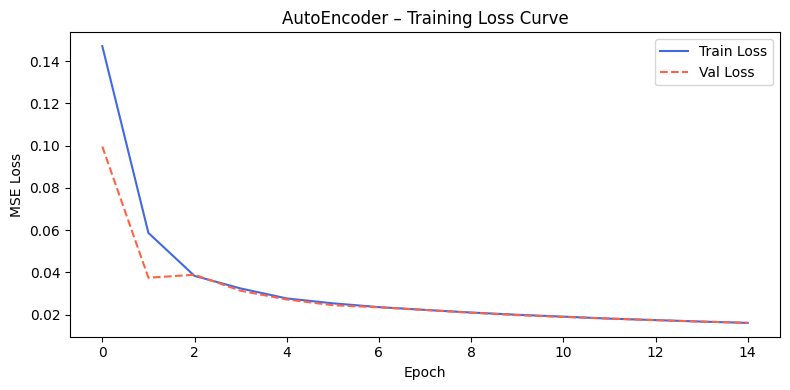

In [49]:
history = autoencoder.fit(
    x_train[:2048], *******[:2048],       # AE는 입력과 정답 모두 원본 이미지입니다.
    epochs=15,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test[:256], x_test[:256]),
    verbose=1
)

# AE 학습 수렴 곡선
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'],     label='Train Loss', color='royalblue')
plt.plot(history.history['val_loss'], label='Val Loss',   color='tomato', linestyle='--')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.title('AutoEncoder – Training Loss Curve')
plt.legend(); plt.tight_layout(); plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 665ms/step


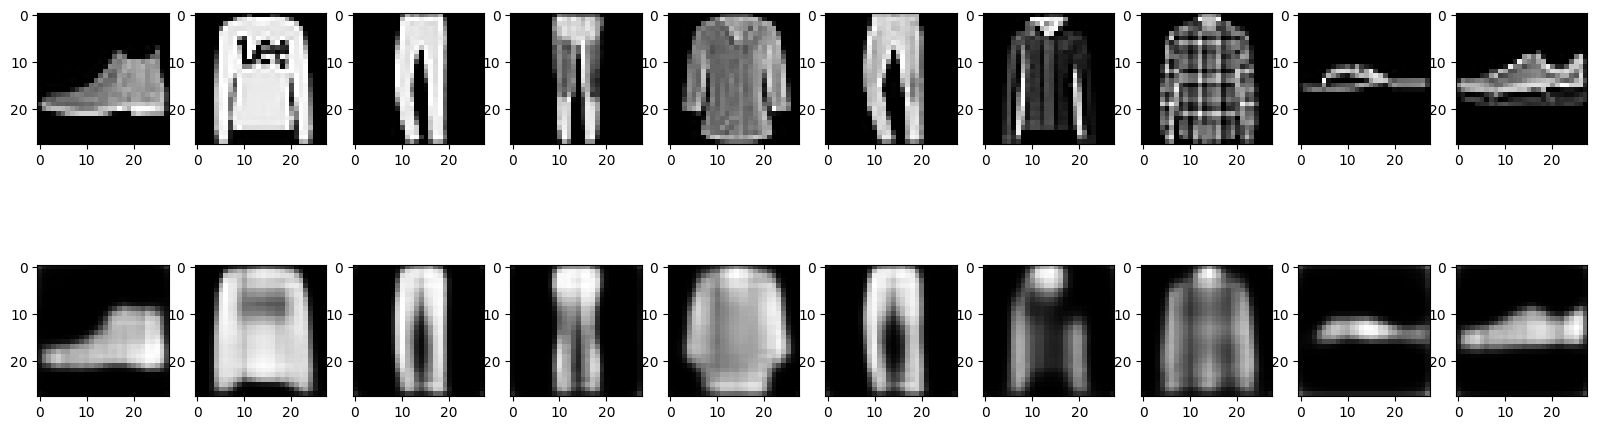

In [50]:
decoded_imgs = autoencoder.predict(x_test[:10])  # 어떤데이터를 예측해야할까요?

n=10
plt.figure(figsize=(20, 6))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28,28), cmap='gray')    #원본이미지

    ax = plt.subplot(2, n, i + n + 1)
    plt.imshow(decoded_imgs[i].reshape(28,28), cmap='gray')   # 재구성된 이미지
plt.show()

#### AE — 원본과 복원 이미지 해석

위의 **원본 이미지(첫째 줄)와 복원 이미지(둘째 줄)**를 비교하세요. 복원 결과에서 유지된 특징과 흐릿해진 특징을 각각 하나씩 찾고, AE가 **압축 후 복원**하는 이유를 강의 내용과 연결해 2~3문장으로 설명하세요.

**[답안]**

관찰한 차이 및 해석:


## 2. VAE — 확률적 잠재벡터와 학습

인코더가 예측한 평균과 로그분산으로 잠재벡터를 샘플링하고, 복원 손실과 KL 발산을 함께 최소화해 봅니다.

In [51]:
latent_dim = 32  # 잠재 공간 차원 (Fashion MNIST의 복잡도를 반영해 32로 설정)

# ----- 인코더 -----
encoder_inputs = layers.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
z_mean = layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)

### 재매개변수화와 디코더

`z = μ + σ·ε`를 이용하여 잠재벡터를 샘플링합니다.

In [52]:
# 재매개변수화 트릭


def sampling(args):
    z_mean, z_log_var = args      #z의 평균과 로그분산을 샘플링합니다!
    eps = tf.random.normal(shape=tf.shape(z_mean))   # 무작위성을 줍시다! 무작위는영어로?
    return z_mean + tf.exp(0.5 * z_log_var) * ***   # return값이 잠재벡터 z의 공식이 됩니다.

z = layers.Lambda(sampling, name="z")([z_mean, z_log_var])
encoder = Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 14, 14,    │        320 │ input_layer_6[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 7, 7, 64)  │     18,496 │ conv2d_15[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3136)      │          0 │ conv2d_16[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │    401,536 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 32)        │      4,128 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 32)        │      4,128 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Lambda)          │ (None, 32)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 428,608 (1.64 MB)

 Trainable params: 428,608 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [53]:
# ----- 디코더 -----
latent_inputs = layers.Input(shape=(latent_dim,))
x = layers.Dense(7 * 7 * 128, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 128))(x)
x = layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)
decoder = Model(latent_inputs, decoder_outputs, name="decoder")  # 디코더의 입력과 출력 변수를 넣어주세요!
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6272)           │       206,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 14, 14, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 28, 28, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 28, 28, 1)      │           577 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 428,929 (1.64 MB)

 Trainable params: 428,929 (1.64 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
z_mu, z_lv, z_sample = encoder(x_test[:1])
print("잠재 벡터 평균 shape:", z_mu.shape)
print("샘플링 잠재 벡터 shape:", z_sample.shape)

# 같은 입력에서 샘플링을 한 번 더 수행하면 값이 달라지는지 확인해 봅시다.
_, _, z_sample_second = encoder(x_test[:1])
print("두 잠재 벡터의 shape:", z_sample.shape, z_sample_second.shape)
print("두 샘플의 평균 절댓값 차이:", float(tf.reduce_mean(tf.abs(z_sample - z_sample_second))))

잠재 벡터 평균 shape: (1, 32)
샘플링 잠재 벡터 shape: (1, 32)
두 잠재 벡터의 shape: (1, 32) (1, 32)
두 샘플의 평균 절댓값 차이: 1.0502135753631592


### VAE 학습 및 이미지 생성

Epoch 1/10 | total=109.22 | reconstruction=109.13 | KL=0.09
Epoch 2/10 | total=75.90 | reconstruction=73.37 | KL=2.53
Epoch 3/10 | total=60.94 | reconstruction=56.76 | KL=4.18
Epoch 4/10 | total=55.91 | reconstruction=51.75 | KL=4.15
Epoch 5/10 | total=53.58 | reconstruction=49.39 | KL=4.19
Epoch 6/10 | total=51.81 | reconstruction=47.59 | KL=4.21
Epoch 7/10 | total=50.54 | reconstruction=45.69 | KL=4.85
Epoch 8/10 | total=48.85 | reconstruction=43.51 | KL=5.34
Epoch 9/10 | total=47.76 | reconstruction=42.26 | KL=5.51
Epoch 10/10 | total=46.55 | reconstruction=40.74 | KL=5.81


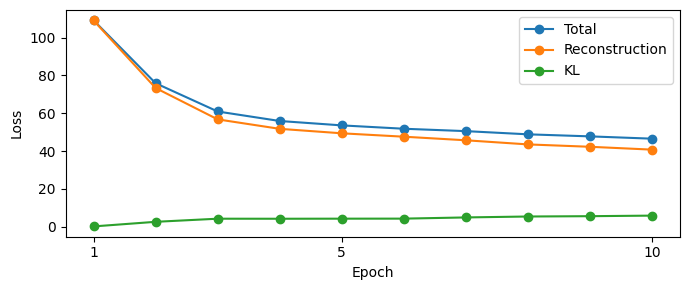

In [55]:
# VAE 학습: 복원 오차와 KL 발산을 함께 최소화합니다.
vae_optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
vae_dataset = tf.data.Dataset.from_tensor_slices(x_train[:2048]).shuffle(2048).batch(128)

@tf.function
def vae_train_step(images):
    with tf.GradientTape() as tape:
        z_mu, z_lv, z_sampled = encoder(images, training=True)
        reconstructed = decoder(z_sampled, training=True)
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(images - reconstructed), axis=[1, 2, 3])
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_lv - tf.square(z_mu) - tf.exp(z_lv), axis=1)
        )
        total_loss = reconstruction_loss + kl_loss

    variables = encoder.trainable_variables + decoder.trainable_variables
    gradients = tape.gradient(total_loss, variables)
    vae_optimizer.apply_gradients(zip(gradients, variables))
    return total_loss, reconstruction_loss, kl_loss

vae_history = {'total': [], 'reconstruction': [], 'kl': []}
VAE_EPOCHS = 10
for epoch in range(VAE_EPOCHS):
    losses = []
    for images in vae_dataset:
        losses.append(vae_train_step(images))
    mean_losses = tf.reduce_mean(tf.stack(losses), axis=0).numpy()
    for key, value in zip(vae_history, mean_losses):
        vae_history[key].append(float(value))
    print(f"Epoch {epoch + 1}/{VAE_EPOCHS} | total={mean_losses[0]:.2f} | "
          f"reconstruction={mean_losses[1]:.2f} | KL={mean_losses[2]:.2f}")

plt.figure(figsize=(7, 3))
for key, label in [('total', 'Total'), ('reconstruction', 'Reconstruction'), ('kl', 'KL')]:
    plt.plot(range(1, VAE_EPOCHS + 1), vae_history[key], marker='o', label=label)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks([1, 5, 10])
plt.legend()
plt.tight_layout()
plt.show()

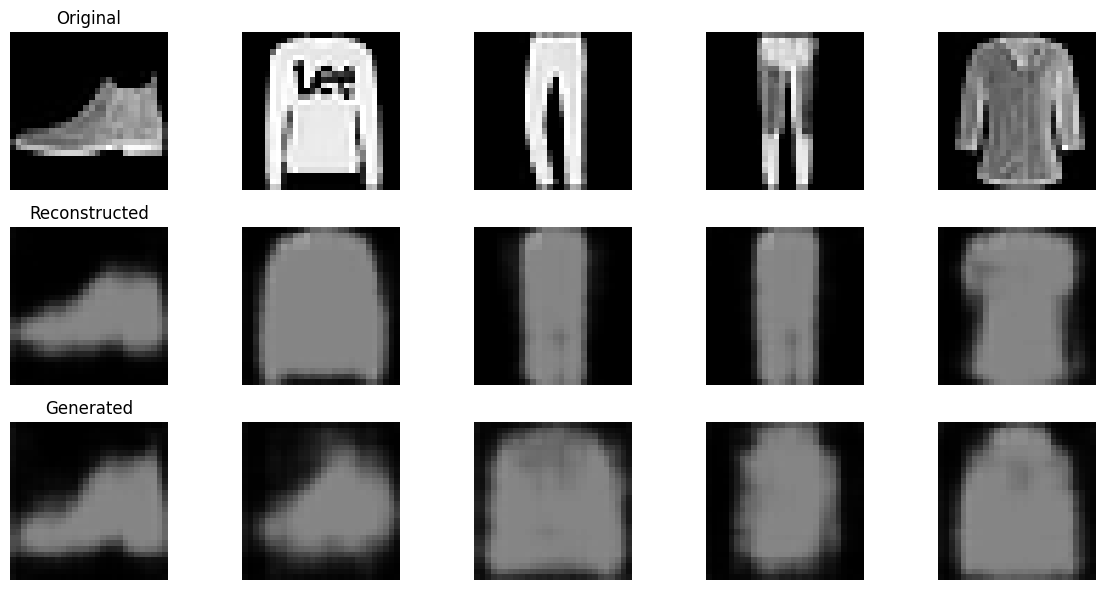

In [56]:
# 학습된 VAE의 복원과 새로운 이미지 생성 결과를 비교합니다.
original = x_test[:5]
_, _, latent_samples = encoder(original, training=False)
reconstructed = decoder(latent_samples, training=False).numpy()
new_latent = tf.random.normal(shape=(5, latent_dim))
generated = decoder(new_latent, training=False).numpy()

plt.figure(figsize=(12, 6))
for i in range(5):
    for row, imgs, label in [(0, original, 'Original'),
                             (1, reconstructed, 'Reconstructed'),
                             (2, generated, 'Generated')]:
        ax = plt.subplot(3, 5, row * 5 + i + 1)
        ax.imshow(imgs[i, :, :, 0], cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
        if i == 0:
            ax.set_title(label)
plt.tight_layout()
plt.show()

#### VAE — 학습과 이미지 생성 결과 해석

학습 손실과 원본·복원·생성 이미지의 차이를 확인하세요. VAE에서 복원 손실과 KL 발산을 함께 사용하는 이유를 설명하고, `z = μ + σ·ε`의 역할을 연결해 작성하세요.

**[답안]**



## 3. GAN — 생성자와 판별자 학습

생성자와 판별자를 20에폭 동안 번갈아 학습하고 손실과 생성 이미지를 비교합니다.

In [57]:
# Fashion MNIST 데이터 로드
(x_train, _), (_, _) = tf.keras.datasets.fashion_mnist.load_data()

# [0, 1] → [-1, 1] 스케일링 (GAN에서는 tanh 출력 맞추기 위함)
x_train = (x_train.astype(np.float32) - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

BUFFER_SIZE = 60000
BATCH_SIZE = 32

# tf.data로 배치 구성
train_dataset = tf.data.Dataset.from_tensor_slices(x_train[:1024]).shuffle(1024).batch(BATCH_SIZE)

In [58]:
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(7*7*256, use_bias=False, input_shape=(100,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
    ])
    return model

generator = make_generator_model()  #위에서 정의한 생성자 함수!
generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

 Trainable params: 2,305,472 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

In [59]:
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same',
                      input_shape=[28, 28, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

discriminator = make_discriminator_model()  #위에서 정의한 판별자 함수!
discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# 손실 함수 정의
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def generator_loss(fake_output):
    # 생성자는 판별자를 '진짜'라고 속여야 하므로 레이블 = 1
    return cross_entropy(tf.*********(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    # 판별자는 진짜=1, 가짜=0 으로 분류해야 함
    real_loss = cross_entropy(tf.ones_like(real_output),  real_output)
    fake_loss = cross_entropy(tf.**********(fake_output), fake_output)
    return real_loss + fake_loss        # 총 손실은 두 손실의 합입니다!

# GAN 학습 안정화를 위해 beta_1=0.5 사용 (일반적인 GAN 권장 설정)
generator_optimizer     = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

noise_dim = 100
num_examples_to_generate = 16

# 고정 시드(매번 같은 예시 생성)
seed = tf.random.normal([num_examples_to_generate, noise_dim])

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss

Epoch 1/20 | Generator Loss: 0.6075 | Discriminator Loss: 1.2365
Epoch 2/20 | Generator Loss: 0.5922 | Discriminator Loss: 1.2900
Epoch 3/20 | Generator Loss: 0.7035 | Discriminator Loss: 1.1882
Epoch 4/20 | Generator Loss: 0.6686 | Discriminator Loss: 1.2531
Epoch 5/20 | Generator Loss: 0.6609 | Discriminator Loss: 1.4112
Epoch 6/20 | Generator Loss: 0.6749 | Discriminator Loss: 1.3868
Epoch 7/20 | Generator Loss: 0.6949 | Discriminator Loss: 1.3929
Epoch 8/20 | Generator Loss: 0.6534 | Discriminator Loss: 1.4475
Epoch 9/20 | Generator Loss: 0.7197 | Discriminator Loss: 1.3181
Epoch 10/20 | Generator Loss: 0.6745 | Discriminator Loss: 1.4180
Epoch 11/20 | Generator Loss: 0.7600 | Discriminator Loss: 1.3219
Epoch 12/20 | Generator Loss: 0.7183 | Discriminator Loss: 1.3385
Epoch 13/20 | Generator Loss: 0.8087 | Discriminator Loss: 1.2387
Epoch 14/20 | Generator Loss: 0.7176 | Discriminator Loss: 1.3319
Epoch 15/20 | Generator Loss: 0.6717 | Discriminator Loss: 1.3845
Epoch 16/20 | Gener

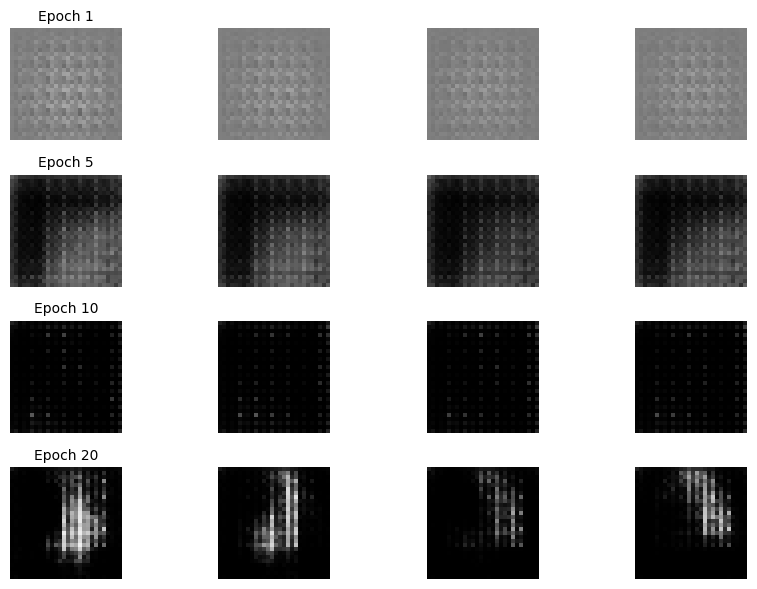

In [61]:
# 고정된 노이즈로 학습에 따른 생성 이미지 변화를 비교합니다.
GAN_EPOCHS = 20
snapshots = {}
snapshot_epochs = [1, 5, 10, 20]
gan_history = {'generator': [], 'discriminator': []}

for epoch in range(GAN_EPOCHS):
    gen_losses, disc_losses = [], []
    for images in train_dataset.take(16):
        gen_loss, disc_loss = train_step(images)
        gen_losses.append(float(gen_loss))
        disc_losses.append(float(disc_loss))

    mean_gen = float(np.mean(gen_losses))
    mean_disc = float(np.mean(disc_losses))
    gan_history['generator'].append(mean_gen)
    gan_history['discriminator'].append(mean_disc)
    if (epoch + 1) in snapshot_epochs:
        snapshots[epoch + 1] = generator(seed[:4], training=False).numpy()
    print(f"Epoch {epoch + 1}/{GAN_EPOCHS} | "
          f"Generator Loss: {mean_gen:.4f} | Discriminator Loss: {mean_disc:.4f}")

plt.figure(figsize=(9, 6))
for row, epoch in enumerate(snapshot_epochs):
    samples = snapshots[epoch]
    for idx in range(4):
        ax = plt.subplot(len(snapshot_epochs), 4, row * 4 + idx + 1)
        ax.imshow(samples[idx, :, :, 0], cmap='gray', vmin=-1, vmax=1)
        ax.axis('off')
        if idx == 0:
            ax.set_title(f'Epoch {epoch}', fontsize=10)
plt.tight_layout()
plt.show()

#### GAN — 학습 결과 해석

각 에폭의 손실값과 생성 이미지를 비교하세요. 생성자와 판별자의 역할을 설명하고, 같은 노이즈에서 만든 이미지가 학습에 따라 어떻게 변했는지 작성하세요.

**[답안]**



## 4. Diffusion — 순확산

원본 이미지에 노이즈를 점차 추가하는 과정을 시각화합니다.

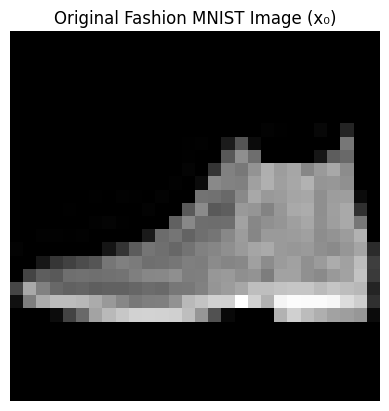

In [62]:
# 앞서 AE에서 준비한 Fashion MNIST 이미지를 사용합니다.
device = "cpu"  # 순확산 시각화만 수행하므로 GPU 불필요
x0_sample = torch.tensor(x_test[0]).permute(2, 0, 1).float()

plt.imshow(x0_sample.squeeze(), cmap='gray')
plt.axis('off')
plt.title("Original Fashion MNIST Image (x₀)")
plt.show()

In [63]:
T = 300  # total diffusion steps
beta = torch.linspace(1e-4, 0.02, T).to(device)
alpha = 1 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

# 배치 단위로 노이즈 추가
def add_noise(x0, t):
    noise = torch.randn_like(x0)
    sqrt_ab = torch.sqrt(alpha_bar[t]).view(-1, 1, 1, 1)    # 원본데이터(x0)에 곱해지는 가중치
    sqrt_1_ab = torch.sqrt(1 - alpha_bar[t]).view(-1, 1, 1, 1)    # 노이즈(noise)에 곱해지는 가중치
    return sqrt_ab * x0 + sqrt_1_ab * *****   # 가중치에 원본데이터와 노이즈를 곱해줍시다!

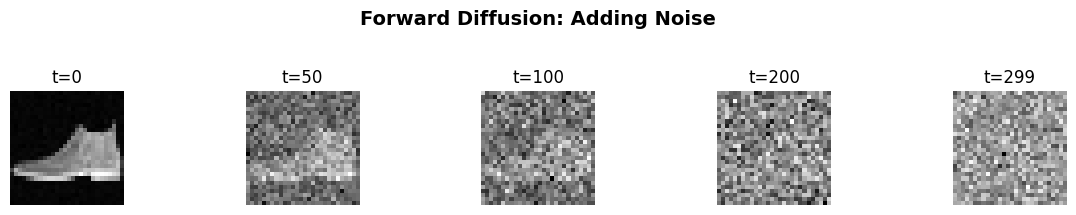

In [64]:
# 순확산 시각화 (샘플 한 장)
x0 = x0_sample.unsqueeze(0).to(device)  # [1,1,28,28]
plt.figure(figsize=(12, 2))
for i, t in enumerate([0, 50, 100, 200, 299]):
    xt = add_noise(x0, torch.tensor([t], device=device))
    plt.subplot(1, 5, i + 1)
    plt.imshow(xt.squeeze().cpu(), cmap='gray')
    plt.axis('off')
    plt.title(f"t={t}")
plt.suptitle("Forward Diffusion: Adding Noise", y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Diffusion — 순확산 결과 해석

그림에서 `t`가 증가할수록 이미지가 어떻게 변화하나요? 이 결과가 순확산에 해당하는 이유와, 새로운 이미지를 생성하기 위해 역확산에서 추가로 필요한 과정을 설명하세요.

**[답안]**



## 수고하셨습니다!